In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

from sklearn import mixture
from sklearn import manifold
from sklearn import pipeline
from sklearn import preprocessing
from sklearn import cluster
from sklearn import metrics
from sklearn import model_selection
from sklearn import decomposition
from sklearn import ensemble
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import warnings 

from IPython.display import display, HTML

warnings.filterwarnings("ignore")

plt.rcParams["patch.force_edgecolor"] = True

In [2]:
data = pd.read_csv(
    "C:\\IDE\\data\\Project-6_Client_Clustering\\customer_segmentation_project.csv", 
    encoding="ISO-8859-1", 
    dtype={'CustomerID': str,'InvoiceID': str}
)
print('Data shape: {}'.format(data.shape))
data.head(5)

Data shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


In [3]:
# 1.1
# Выводим информацию о данных
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB


In [4]:
# 1.2
# Смотрим на пропуски
data.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
# 1.3
# Преобразуем признак InvoiceDate в формат datetime и посмотрим на временной промежуток данных
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
print("Первая транзакция {}, последняя транзакция {}".format(data['InvoiceDate'].min(), data['InvoiceDate'].max()))

Первая транзакция 2010-12-01 08:26:00, последняя транзакция 2011-12-09 12:50:00


In [6]:
# 1.4
# Выводим макисмальное кол-во товаров при заказе
print("Максимальное количество товаров в заказе: {}".format(round(data['Quantity'].max())))
# Выводим минимальное кол-во товаров при заказе
print("Минимальное количество товаров в заказе: {}".format(round(data['Quantity'].min())))
# Выводим минимальную стоимость товара
print("Цена самого дешевого товара в заказе: {}".format(round(data.loc[data['UnitPrice'] > 0, 'UnitPrice'].min())))

Максимальное количество товаров в заказе: 80995
Минимальное количество товаров в заказе: -80995
Цена самого дешевого товара в заказе: 0


In [7]:
# 1.5

print("Число уникальных клиентов: {}".format(data['CustomerID'].nunique()))
print("Количество уникальных стран: {}".format(len(data[data['Country']!= 'Unspecified']['Country'].unique())))
print("Код самого популярного товара: {}".format(data['StockCode'].mode()))

Число уникальных клиентов: 4372
Количество уникальных стран: 37
Код самого популярного товара: 0    85123A
Name: StockCode, dtype: object


In [8]:
# 2.1
# Смотрим общее количество пропусков
print("Количество пропусков в данных: {}".format(data.isnull().sum().sum()))
# Удаляем строки с пропусками
data = data.dropna(subset=['CustomerID', 'Description'])
data.shape[0]

Количество пропусков в данных: 136534


406829

In [9]:
# 2.2
# Проверем количество дубликатов
print("Количество дубликатов в данных: {}".format(data.duplicated().sum()))
# Удаляем дубликаты
data = data.drop_duplicates()
data.shape

Количество дубликатов в данных: 5225


(401604, 8)

In [10]:
# Посмотрим на данные в которых количество товаров меньше нуля

negative_quantity = data[(data['Quantity']<0)]
print('Count of entries with a negative number: {}'.format(negative_quantity.shape[0]))
negative_quantity.head()

Count of entries with a negative number: 8872


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom


In [11]:
# 2.3
# Проверим, есть ли в данных с отрицательным количеством товара, транзакции не являющиеся возвратами
not_cancelled = negative_quantity[~negative_quantity['InvoiceNo'].astype(str).str.startswith('C')]
not_cancelled.shape

(0, 8)

In [12]:
# Подсчитаем количество возвратов, определив сколько уникальных товаров указано в транзакции для каждой уникальной пары клиент-заказ

temp = data.groupby(by=['CustomerID', 'InvoiceNo'], as_index=False)['InvoiceDate'].count()
nb_products_per_basket = temp.rename(columns = {'InvoiceDate':'Number of products'})
nb_products_per_basket.head()

,CustomerID,InvoiceNo,Number of products
0,12346,541431,1
1,12346,C541433,1
2,12347,537626,31
3,12347,542237,29
4,12347,549222,24


In [13]:
# 2.4
# Создаем признак отмены заказа (1 - если начинается на 'C', иначе 0)
nb_products_per_basket['order_canceled'] = nb_products_per_basket['InvoiceNo'].astype(str).str.startswith('C').astype(int)

# Считаем процент возвратов
canceled_share = nb_products_per_basket['order_canceled'].mean() * 100
print(f"Процент возвратов в таблице: {canceled_share:.0f}%")

Процент возвратов в таблице: 16%


In [14]:
# Посмотрим на отмененные заказы
nb_products_per_basket[nb_products_per_basket['order_canceled']==1].head()

,CustomerID,InvoiceNo,Number of products,order_canceled
1,12346,C541433,1,1
23,12352,C545329,2,1
24,12352,C545330,1,1
25,12352,C547388,7,1
39,12359,C549955,2,1


In [15]:
data[data['CustomerID'] == '12346']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom


In [16]:
# 2.5
# Выдвигаем гипотезу: для каждой отменённой транзакции в базе данных (таблица data)
# существует её аналог с тем же кодом товара, идентификатором клиента и противоположным значением количества товара.

# Флаг подтверждения гипотезы
hypothesis_is_true = True

# Проходим циклом по каждой строке с отрицательным количеством
for index, row in negative_quantity.iterrows():
    # Ищем зеркальную запись в основном датасете data
    matching_records = data[
        (data['CustomerID'] == row['CustomerID']) & 
        (data['StockCode'] == row['StockCode']) & 
        (data['Quantity'] == -row['Quantity'])
    ]
    
    # Если не нашлось ни одной такой записи, гипотеза неверна
    if matching_records.empty:
        hypothesis_is_true = False
        print(f"Гипотеза неверна! Для отмены на строке {index} нет пары.")
        print(f"Клиент: {row['CustomerID']}, Товар: {row['StockCode']}, Кол-во в отмене: {row['Quantity']}")
        break  # Останавливаем цикл при первой же ошибке

if hypothesis_is_true:
    print("Гипотеза верна! Для каждой отмены в датасете есть исходный заказ.")

Гипотеза неверна! Для отмены на строке 141 нет пары.
Клиент: 14527, Товар: D, Кол-во в отмене: -1


In [17]:
data[data['CustomerID'] == '14527'].head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
8963,537159,22112,CHOCOLATE HOT WATER BOTTLE,6,2010-12-05 13:17:00,4.95,14527,United Kingdom
8964,537159,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-05 13:17:00,4.95,14527,United Kingdom
8965,537159,21479,WHITE SKULL HOT WATER BOTTLE,1,2010-12-05 13:17:00,3.75,14527,United Kingdom
8966,537159,22114,HOT WATER BOTTLE TEA AND SYMPATHY,6,2010-12-05 13:17:00,3.95,14527,United Kingdom


In [18]:
# 2.6
#Выдвигаем новую гипотезу: для каждой отменённой транзакции в базе данных (таблица data) 
# существует её аналог с тем же кодом товара, идентификатором клиента и противоположным значением количества товара, 
# если на товар не распространяются скидки.

# Задаем маску для фильтрации скидок (настройте под свой датасет)
# Исключаем коды 'D' (Discount) и строки, где в описании есть слово 'discount'
is_discount_in_data = (data['StockCode'].astype(str).str.upper() == 'D') | \
                      (data['Description'].astype(str).str.lower().str.contains('Discount', na=False))

is_discount_in_neg = (negative_quantity['StockCode'].astype(str).str.upper() == 'D') | \
                     (negative_quantity['Description'].astype(str).str.lower().str.contains('Discount', na=False))

# Фильтруем данные, оставляя только транзакции БЕЗ скидок
data_no_discounts = data[~is_discount_in_data]
neg_no_discounts = negative_quantity[~is_discount_in_neg]

hypothesis_is_true = True
checked_count = 0

for index, row in neg_no_discounts.iterrows():
    # Проверяем, нет ли скидки в текущей строке (на случай, если не фильтровали заранее)
    if str(row['StockCode']).upper() == 'D' or 'Discount' in str(row['Description']).lower():
        continue
        
    checked_count += 1
    # Ищем зеркальную запись в data_no_discounts
    matching_records = data_no_discounts[
        (data_no_discounts['CustomerID'] == row['CustomerID']) & 
        (data_no_discounts['StockCode'] == row['StockCode']) & 
        (data_no_discounts['Quantity'] == -row['Quantity'])
    ]
    
    if matching_records.empty:
        hypothesis_is_true = False
        print(f"Пара не найдена для строки {index} (Клиент: {row['CustomerID']}, Товар: {row['StockCode']})")
        break

if hypothesis_is_true:
    print(f"Гипотеза верна! Успешно проверено транзакций без скидок: {checked_count}")

Пара не найдена для строки 154 (Клиент: 15311, Товар: 35004C)


In [19]:
data[(data['CustomerID'] == '15311') & (data['StockCode'] == '35004C')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
9200,537195,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2010-12-05 13:55:00,4.65,15311,United Kingdom
18196,C537805,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-08 13:18:00,4.65,15311,United Kingdom
28630,538651,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2010-12-13 15:07:00,4.65,15311,United Kingdom
39381,C539640,35004C,SET OF 3 COLOURED FLYING DUCKS,-3,2010-12-20 15:27:00,4.65,15311,United Kingdom
44157,540157,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2011-01-05 11:41:00,4.65,15311,United Kingdom
59542,541293,35004C,SET OF 3 COLOURED FLYING DUCKS,12,2011-01-17 13:39:00,4.65,15311,United Kingdom
78333,C542866,35004C,SET OF 3 COLOURED FLYING DUCKS,-2,2011-02-01 12:14:00,4.65,15311,United Kingdom


In [20]:
# 2.7

def get_quantity_canceled(data):
    # Инициализируем нулями Series той же длины, что и столбцы таблицы
    quantity_canceled = pd.Series(np.zeros(data.shape[0]), index=data.index)    
    negative_quantity = data[(data['Quantity'] < 0)].copy()
    for index, col in negative_quantity.iterrows():
        # Создаём DataFrame из всех транзакций, противоположных возвратам
        df_test = data[(data['CustomerID'] == col['CustomerID']) &
                       (data['StockCode']  == col['StockCode']) & 
                       (data['InvoiceDate'] < col['InvoiceDate']) & 
                       (data['Quantity'] > 0)].copy()
        # Транзация-возврат не имеет противоположной — ничего не делаем
        if (df_test.shape[0] == 0): 
            continue
        # Транзакция-возврат имеет только одну противоположную транзакцию
        # Добавляем количество возвращённого товара в столбец QuantityCanceled 
        elif (df_test.shape[0] == 1): 
            index_order = df_test.index[0]
            quantity_canceled.loc[index_order] = -col['Quantity']       
        # Транзакция-возврат имеет несколько противоположных транзакций
        # Вносим количество возвращённого товара в столбец QuantityCanceled для той транзакции на покупку,
        # в которой количество товара > (-1) * (количество товаров в транзакции-возврате)
        elif (df_test.shape[0] > 1): 
            df_test.sort_index(axis=0 ,ascending=False, inplace = True)        
            for ind, val in df_test.iterrows():
                if val['Quantity'] < -col['Quantity']: 
                    continue
                quantity_canceled.loc[ind] = -col['Quantity']
                break    
    return quantity_canceled

data['QuantityCanceled'] = get_quantity_canceled(data)

In [21]:
data['QuantityCanceled'].sum()

245266.0

In [22]:
# 2.8
# Удаляем из данных строки, в которых указано отрицательное количество товара. Они нам не понадобятся
data = data[data['Quantity'] >= 0]
data.shape

(392732, 9)

In [23]:
# 2.9
# Приводим к строковому типу, чтобы избежать ошибок с числами
stock_codes_str = data['StockCode'].astype(str)

# Находим маску для специальных кодов товаров
special_mask = stock_codes_str.str.contains('^[a-zA-Z]', regex=True)

# Получаем список уникальных специальных кодов
unique_special_codes = data.loc[special_mask, 'StockCode'].unique()

print(f"1) Уникальные специальные виды транзакций ({len(unique_special_codes)} шт.):")
print(unique_special_codes)

# Удаляем специальные транзакции (оставляем те, что НЕ подходят под маску)
data = data[~special_mask]

print(f"\n2) Количество записей, оставшихся в таблице: {data.shape[0]}")

1) Уникальные специальные виды транзакций (6 шт.):
['POST' 'C2' 'M' 'BANK CHARGES' 'PADS' 'DOT']

2) Количество записей, оставшихся в таблице: 391183


In [24]:
# 2.10

# Посмотрим на количество транзакций с нулевой стоимостью товара
print("Количество транзакций с нулевой стоимостью: {}".format(data[data['UnitPrice']==0].shape[0]))
# Удаляем строки с такими транзакциями из таблицы(их очень мало)
data = data[data['UnitPrice'] > 0]
data.shape

Количество транзакций с нулевой стоимостью: 33


(391150, 9)

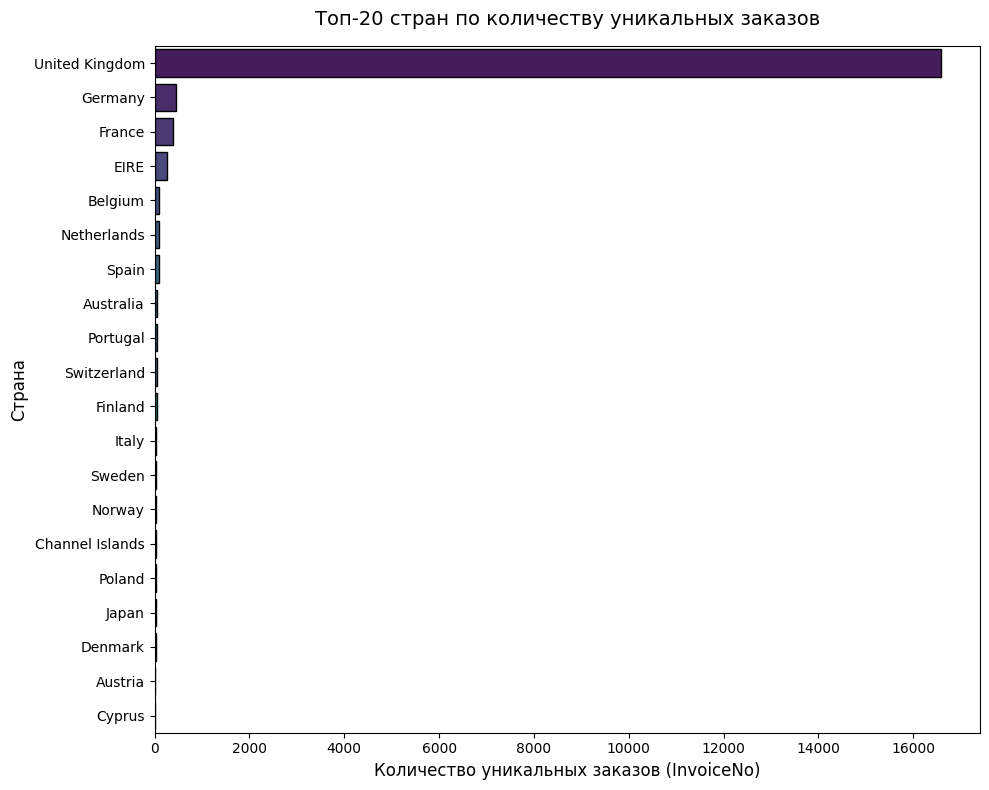

In [25]:
# 3.1

# Посмотрим на количество уникальных клиентов по странам
clien_data = data.groupby(by=['Country'],as_index=False)['InvoiceNo'].nunique()
# Сортируем по убыванию и берем Топ-20 стран
clien_data = clien_data.sort_values(by='InvoiceNo', ascending=False).head(20)

# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='InvoiceNo', 
    y='Country', 
    data=clien_data, 
    palette='viridis'
)

plt.title('Топ-20 стран по количеству уникальных заказов', fontsize=14, pad=15)
plt.xlabel('Количество уникальных заказов (InvoiceNo)', fontsize=12)
plt.ylabel('Страна', fontsize=12)
plt.tight_layout()

plt.show()

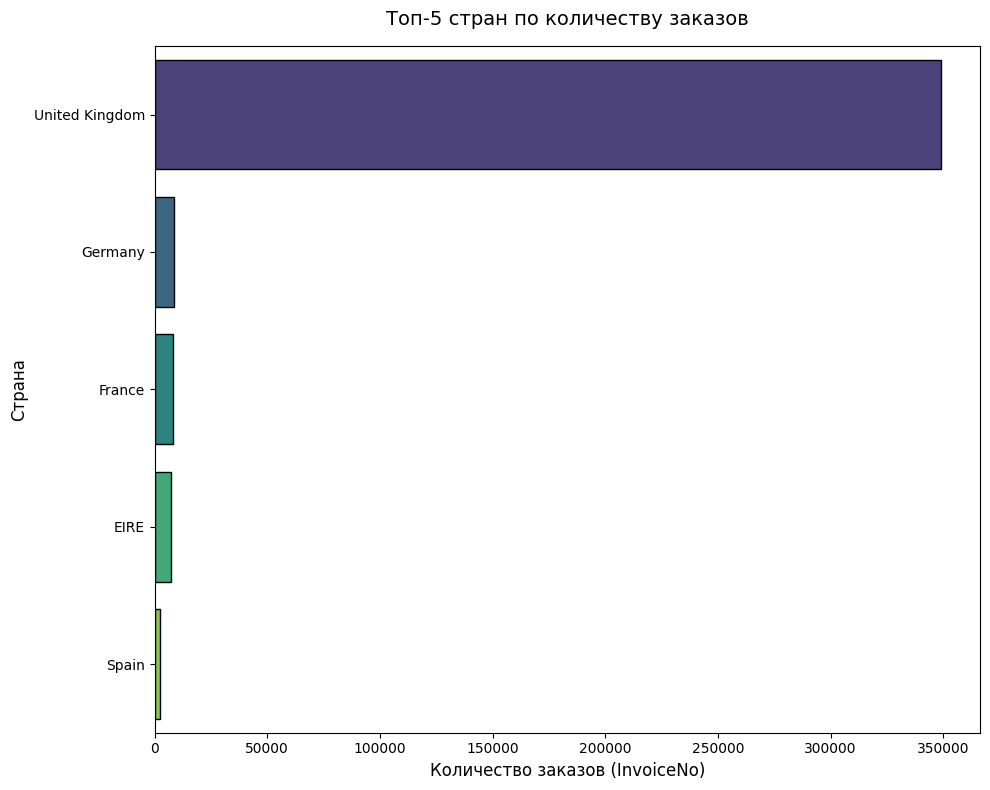

In [26]:
# 3.2

# Посмотрим на количество заказов по странам
clien_data = data.groupby(by=['Country'],as_index=False)['InvoiceNo'].count()
# Сортируем по убыванию и берем Топ-5 стран
clien_data = clien_data.sort_values(by='InvoiceNo', ascending=False).head(5)

# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='InvoiceNo', 
    y='Country', 
    data=clien_data, 
    palette='viridis'
)

plt.title('Топ-5 стран по количеству заказов', fontsize=14, pad=15)
plt.xlabel('Количество заказов (InvoiceNo)', fontsize=12)
plt.ylabel('Страна', fontsize=12)
plt.tight_layout()

plt.show()

In [27]:
# 3.3
# Создаем признак общей стоимости TotalPrice для каждой строки с учетом возвратов
data["TotalPrice"] = data["UnitPrice"] * (
    data["Quantity"] - data["QuantityCanceled"]
)

# Посмотрим на среднюю цену
print("Средняя стоимость заказа: {}".format(round(data['TotalPrice'].mean())))

Средняя стоимость заказа: 21


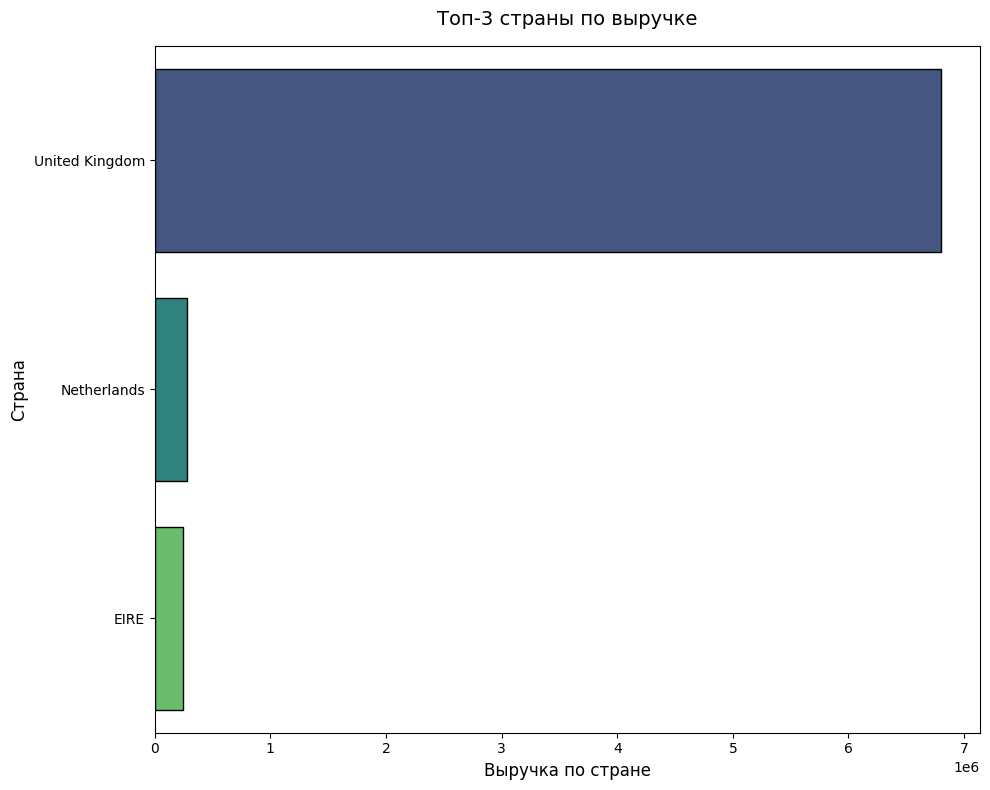

In [28]:
# 3.4
# Посмотрим на выручку по странам
total_price_data = data.groupby(by=['Country'],as_index=False)['TotalPrice'].sum()
# Сортируем по убыванию и берем Топ-3 страны
total_price_data = total_price_data.sort_values(by='TotalPrice', ascending=False).head(3)

# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='TotalPrice', 
    y='Country', 
    data=total_price_data, 
    palette='viridis'
)

plt.title('Топ-3 страны по выручке', fontsize=14, pad=15)
plt.xlabel('Выручка по стране', fontsize=12)
plt.ylabel('Страна', fontsize=12)
plt.tight_layout()

plt.show()

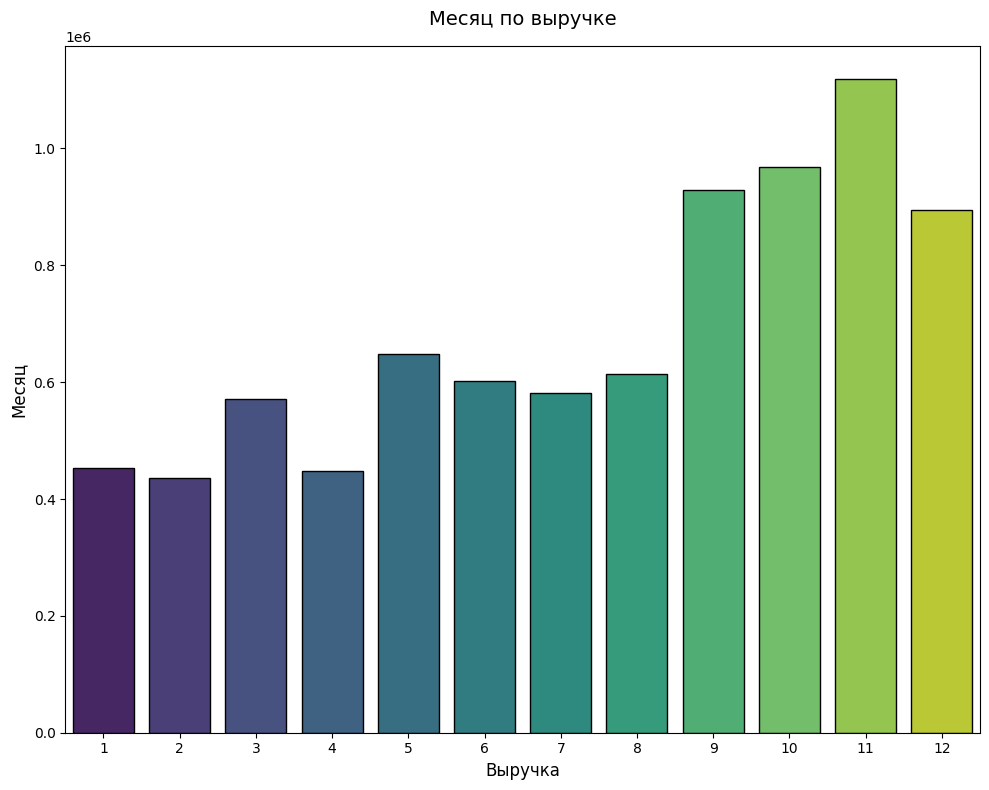

In [29]:
# 3.5
# Создадим три новых признака даты
def add_datetime_features(DataFrame):
    """Функция принимает на вход DataFrame и возвращает три новых признака в формате datetime:
           Признак номера месяца,
           Признак названия дня недели,
           Признак часа совершения покупки

    Args:
        DataFrame (DataFrame): DataFrame с данными о транзакциях
    """
    
    data['Month'] = pd.to_datetime(data['InvoiceDate']).dt.month
    
    data['Weekday'] = pd.to_datetime(data['InvoiceDate']).dt.day_name()
    
    data['Tranzaction_Hour'] = pd.to_datetime(data['InvoiceDate']).dt.hour
    
add_datetime_features(DataFrame=data)

# Посмотрим какая выручка была по месяцам
month_price = data.groupby(by=['Month'],as_index=False)['TotalPrice'].sum()

# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Month', 
    y='TotalPrice', 
    data=month_price, 
    palette='viridis'
)

plt.title('Месяц по выручке', fontsize=14, pad=15)
plt.xlabel('Выручка', fontsize=12)
plt.ylabel('Месяц', fontsize=12)
plt.tight_layout()

plt.show()

### Как мы видим, самым прибыльным месяцем является Ноябрь. Вероятная причина в том что, данный месяц предшевствует Декабрю и новогодним праздникам, что увеличивает количество заказов на возможные подарки.

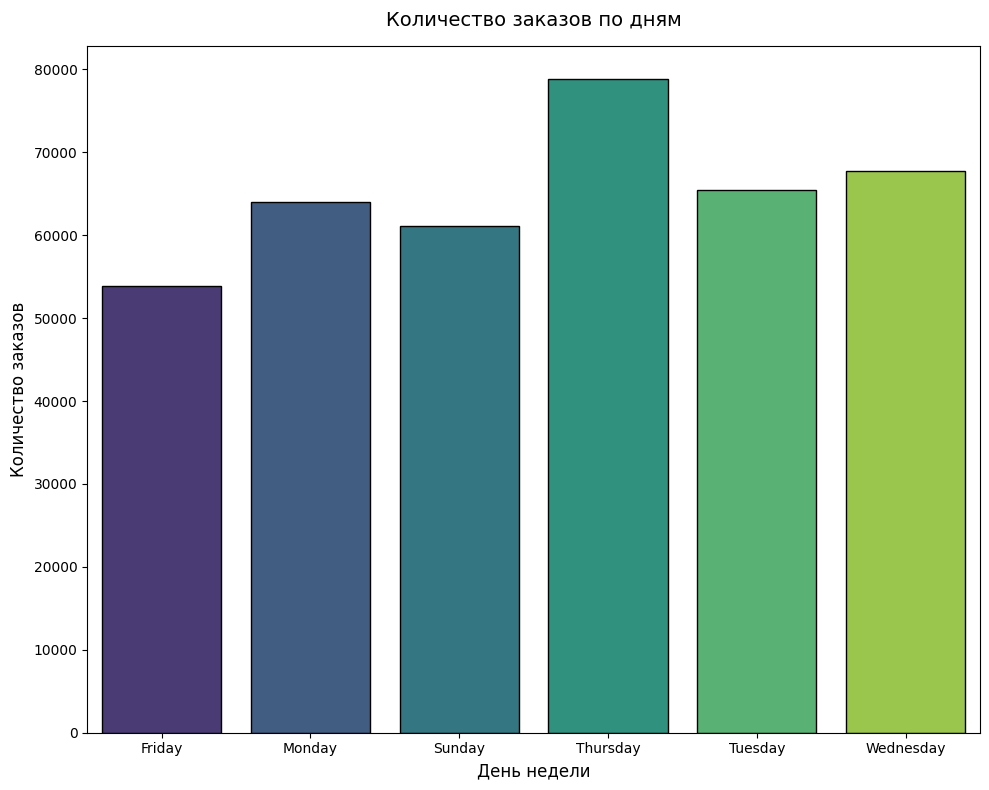

In [30]:
# 3.6
# Посмотрим на количество заказов в зависимости от дня недели
weekday_order = data.groupby(by=['Weekday'],as_index=False)['InvoiceNo'].count()

# Строим график
plt.figure(figsize=(10, 8))
sns.barplot(
    x='Weekday', 
    y='InvoiceNo', 
    data=weekday_order, 
    palette='viridis'
)

plt.title('Количество заказов по дням', fontsize=14, pad=15)
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
plt.tight_layout()

plt.show()


### Отсутствует суббота. Это может быть выходной день в компании или ошибка в данных.

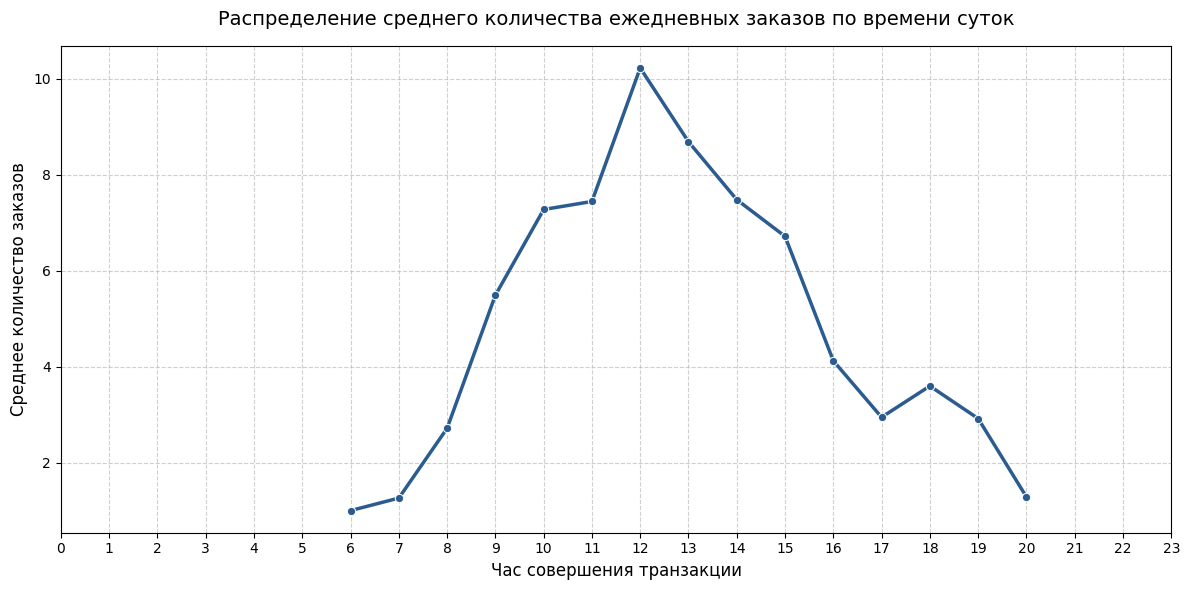

In [31]:
# 3.7
# Выделим дату из признака времени совершения транзакции. 
# Сгруппируем данные по датам и часам совершения транзакции и найдем количество заказов на каждый день-час. 
# Затем найдем среднее количество ежедневно поступающих заказов в каждый из часов.
# Выделяем дату
data["Date"] = data["InvoiceDate"].dt.date

# Считаем количество уникальных заказов на каждый день и час
daily_hourly_orders = (
    data.groupby(["Date", "Tranzaction_Hour"], as_index=False)["InvoiceNo"]
    .nunique()
    .rename(columns={"InvoiceNo": "Orders_Count"})
)

# Находим среднее количество ежедневных заказов для каждого часа
hourly_avg_orders = daily_hourly_orders.groupby(
    "Tranzaction_Hour", as_index=False
)["Orders_Count"].mean()

# Строим график
plt.figure(figsize=(12, 6))
sns.lineplot(
    x="Tranzaction_Hour",
    y="Orders_Count",
    data=hourly_avg_orders,
    marker="o",
    linewidth=2.5,
    color="#2b5c8f",
)

plt.title(
    "Распределение среднего количества ежедневных заказов по времени суток",
    fontsize=14,
    pad=15,
)
plt.xlabel("Час совершения транзакции", fontsize=12)
plt.ylabel("Среднее количество заказов", fontsize=12)

# Настраиваем отображение каждого часа на оси X
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

In [32]:
# 4.1
# Создадим RFM-таблицу из наших данных
# Задаем точку отсчета
snapshot_date = pd.to_datetime('2011-12-10 00:00:00')

# Рассчитываем общую сумму для каждого товара в заказе (с учетом возвратов)
data['TotalSum'] = data['Quantity'] * data['UnitPrice']

# Агрегируем данные по клиентам
rfm = data.groupby('CustomerID').agg({
    # Recency: разница между точкой отсчета и датой последнего заказа (в днях)
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    # Frequency: количество уникальных заказов
    'InvoiceNo': 'nunique',
    # Monetary Value: общая сумма потраченных денег
    'TotalSum': 'sum'
})

# Переименовываем столбцы
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalSum': 'Monetary'
}, inplace=True)

# Переводим индекс (CustomerID) в обычный столбец
rfm = rfm.reset_index()

# Просмотр результата
print(rfm.head())

  CustomerID  Recency  Frequency  Monetary
0      12346      325          1  77183.60
1      12347        2          7   4310.00
2      12348       75          4   1437.24
3      12349       18          1   1457.55
4      12350      310          1    294.40


In [33]:
# Просмотрим некоторые данные

# Выведем число клиентов, совершивших покупку более 200 дней назад
rfm_200 = rfm[rfm['Recency']>200]
print('Количество клиентов, совершивших покупку более 200 дней назад: {}'.format(rfm_200.shape[0]))

# Выведем среднее количество заказов
print('Среднее количество заказов, которые делает клиент: {}'.format(round(rfm['Frequency'].mean())))

# Выведем данные случайного клиента
print(rfm[rfm['CustomerID']=='12360'])

Количество клиентов, совершивших покупку более 200 дней назад: 743
Среднее количество заказов, которые делает клиент: 4
   CustomerID  Recency  Frequency  Monetary
13      12360       52          3   2302.06


In [35]:
# Построим коробчатые диаграммы нашей RFM-таблицы
# Отбираем только нужные метрики для графиков (исключаем CustomerID)
metrics = ['Recency', 'Frequency', 'Monetary']
boxes = [px.box(rfm, x=column) for column in metrics]

fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=("Recency", "Frequency", "Monetary")
)

for i, box in enumerate(boxes):
    fig.add_trace(box['data'][0], row=1, col=i+1)

fig.update_layout(showlegend=False, title_text="Распределение метрик RFM")
fig.show()

In [36]:
# 4.2
# Удалим гиппотетические выбросы, данные которые выходят за пределы 0.95 квантилей
# Расчитываем пороговые значения
freq_cutoff = rfm['Frequency'].quantile(0.95)
monetary_cutoff = rfm['Monetary'].quantile(0.95)

# Оставляем только те данные, которые строго меньше или равны порогу
rfm_clean = rfm[
    (rfm['Frequency'] <= freq_cutoff) & 
    (rfm['Monetary'] <= monetary_cutoff)
]

print(rfm_clean.shape[0])

4044


In [37]:
# Снова построим коробчатые диаграммы нашей RFM-таблицы

metrics = ['Recency', 'Frequency', 'Monetary']
boxes = [px.box(rfm_clean, x=column) for column in metrics]

fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=("Recency", "Frequency", "Monetary")
)

for i, box in enumerate(boxes):
    fig.add_trace(box['data'][0], row=1, col=i+1)

fig.update_layout(showlegend=False, title_text="Распределение метрик RFM")
fig.show()

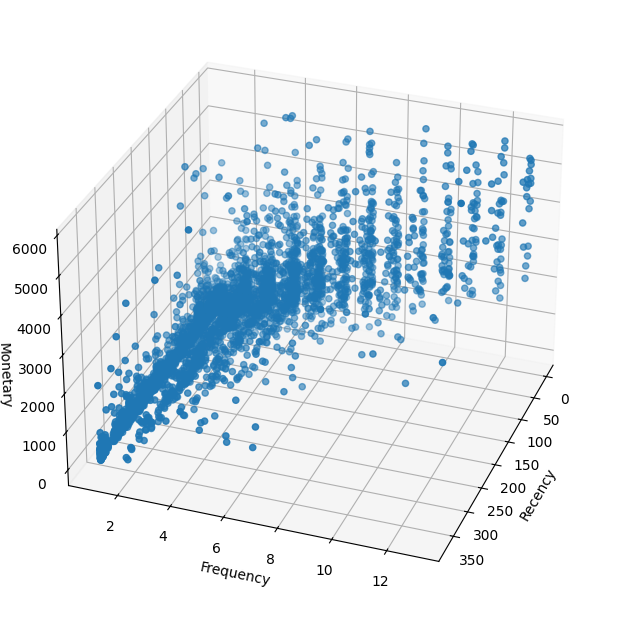

In [38]:
# Посмотрим на распределение наблюдений
# Создадим трёхмерный объект
fig = plt.figure(figsize=(6,6))
ax = Axes3D(fig)
# Добавим дополнительную ось в объект картинки
fig.add_axes(ax)
ax.azim = 20
ax.elev = 30

# Визуализируем данные, передав значения x, y, z, а также информацию о группировке данных по цветам
ax.scatter(
    rfm_clean['Recency'].to_list(), 
    rfm_clean['Frequency'].to_list(),
    rfm_clean['Monetary'].to_list()
)
# Добавим оси
ax.set_xlabel('Recency')
ax.set_ylabel('Frequency')
ax.set_zlabel('Monetary');

In [45]:
# 5.3
# Создадим пайплайн, нормализуем данные, и применим снижение размерности
# Переводим CustomerID в индекс
if 'CustomerID' in rfm_clean.columns:
    rfm_clean = rfm_clean.set_index('CustomerID', inplace=True)
    
# Создаем пайплайн
rfm_pipeline = Pipeline(
    steps=[
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=2))
    ]
)

rfm_pca = rfm_pipeline.fit_transform(rfm_clean)
first_comp_variance = rfm_pipeline['pca'].explained_variance_ratio_[0]

# Выводим результат в процентах
print(f"Первая главная компонента объясняет {first_comp_variance:.2%} исходной дисперсии.")

rfm_pca_df = pd.DataFrame(
    data=rfm_pca, 
    columns=['Component 1', 'Component 2'], 
    index=rfm_clean.index
)

Первая главная компонента объясняет 67.68% исходной дисперсии.


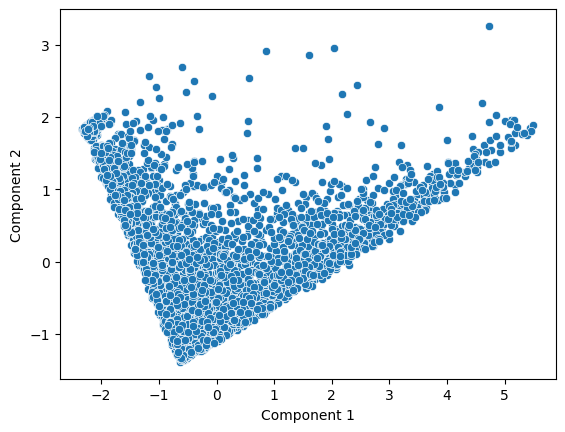

In [46]:
sns.scatterplot(data=rfm_pca_df, x='Component 1', y='Component 2');

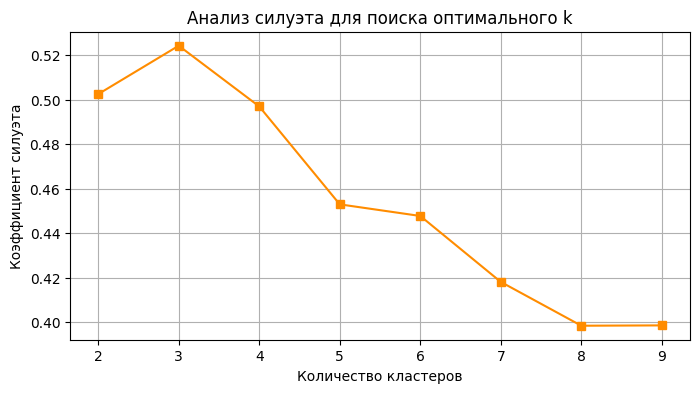

[0.5  0.52 0.5  0.45 0.45 0.42 0.4  0.4 ]


In [48]:
# 4.4
# Используем Kmeans. Найдем оптимальное количество кластеров.
# Создадим функцию, для подсчета лучшего коэффициента силуэта и оптимального количества кластеров
def get_silhouette(cluster_num, rfm_pca_df):
    kmeans = KMeans(init='k-means++', n_clusters=cluster_num, random_state=42)
    kmeans.fit(rfm_pca_df)
    silhouette = silhouette_score(rfm_pca_df, kmeans.labels_)
    return silhouette

silhouette = []
for cluster_num in range(2,10):
    silhouette.append(get_silhouette(cluster_num, rfm_pca_df))

# Создаем график для коэффициента силуэта   
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), silhouette, marker='s', color='darkorange')
plt.title('Анализ силуэта для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.grid(True)
plt.show()

print(np.round(silhouette,2))

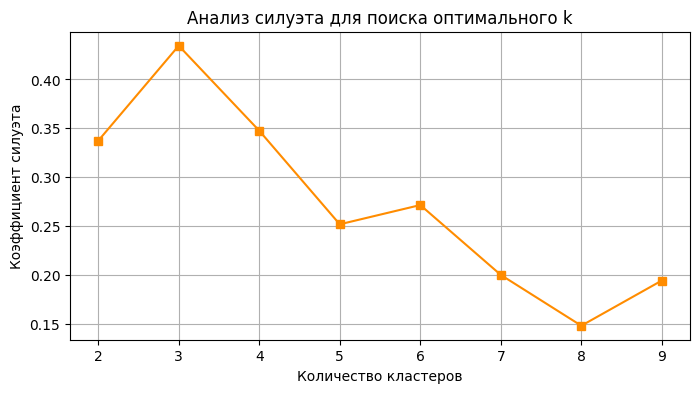

[0.34 0.43 0.35 0.25 0.27 0.2  0.15 0.19]


In [51]:
# 4.5
# Повторим, использую EM-алгоритм
def get_silhouette(cluster_num, rfm_pca_df):
    em = GaussianMixture(n_components=cluster_num, random_state=42)
    labels = em.fit_predict(rfm_pca_df)
    silhouette = silhouette_score(rfm_pca_df, labels)
    return silhouette

silhouette = []
for cluster_num in range(2,10):
    silhouette.append(get_silhouette(cluster_num, rfm_pca_df))
    
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), silhouette, marker='s', color='darkorange')
plt.title('Анализ силуэта для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.grid(True)
plt.show()

print(np.round(silhouette,2))

In [53]:
# 4.6
# Обучим модель используя KMeans, так как он показал лучший коэффициент силуэта
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(rfm_pca_df)
silhouette = silhouette_score(rfm_pca_df, kmeans.labels_)
print(np.bincount(kmeans.labels_))

[ 766 1004 2274]


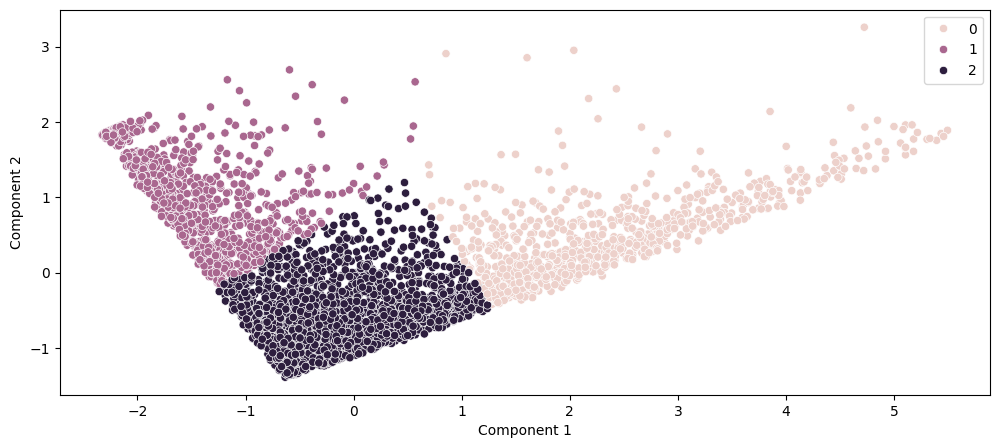

In [54]:
fig = plt.figure(figsize=(12, 5))
sns.scatterplot(
    data=rfm_pca_df, 
    x='Component 1', 
    y='Component 2', 
    hue=kmeans.labels_
);

In [55]:
# 4.7
# Составим профиль кластров. Вернемся к RFM-таблице, очищенной от выбросов
rfm_clean['Cluster'] = kmeans.labels_

# Группируем по кластерам и рассчитываем среднее для каждого признака
cluster_profiles = rfm_clean.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

print(cluster_profiles)
print(round(cluster_profiles['Frequency'].max(),2))

            Recency  Frequency     Monetary
Cluster                                    
0         31.706266   7.126632  2728.081462
1        252.914343   1.407371   401.662729
2         50.890501   2.340369   678.608404
7.13


In [56]:
# 4.8
# Построим полярную диаграмму для нашей кластеризации
def plot_cluster_profile(cluster_profiles, n_clusters):
    # Нормализуем сгруппированные данные, приводя их к масштабу 0-1.
    scaler = preprocessing.MinMaxScaler()
    cluster_profiles = pd.DataFrame(scaler.fit_transform(cluster_profiles), columns=cluster_profiles.columns)
    # Создаем список признаков
    features = cluster_profiles.columns
    # Создаем пустую фигуру
    fig = go.Figure()
    # В цикле визуализируем полярную диаграмму для каждого кластера
    for i in range(n_clusters):
        # Создаем полярную диаграмму и добавляем ее на общий график
        fig.add_trace(go.Scatterpolar(
            r=cluster_profiles.iloc[i].values, # радиусы
            theta=features, # название засечек
            fill='toself', # заливка многоугольника цветом
            name=f'Cluster {i}', # название - номер кластера
        ))
    # Обновляем параметры фигуры
    fig.update_layout(
        showlegend=True, # отображение легенды
        autosize=False, # устаналиваем свои размеры графика
        width=800, # ширина (в пикселях)
        height=800, # высота (в пикселях)
    )
    # Отображаем фигуру
    fig.show()
plot_cluster_profile(cluster_profiles, n_clusters=3)

In [58]:
rfm_clean = rfm_clean.drop('Cluster', axis=1)
rfm_clean

,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,4310.00
12348,75,4,1437.24
12349,18,1,1457.55
12350,310,1,294.40
12352,36,7,1385.74
...,...,...,...
18278,73,1,173.90
18280,277,1,180.60
18281,180,1,80.82


In [62]:
# 5.1
# Создаем пайплайн, стандартизируем данные, применяем понижение размерности методом t-sne
rfm_pipeline = Pipeline(
    steps=[
        ('scaler', StandardScaler()),
        ('tsne', TSNE(n_components=2,perplexity=50, random_state=100))
    ]
)

rfm_pca = rfm_pipeline.fit_transform(rfm_clean)

rfm_pca_df_tsne = pd.DataFrame(
    data=rfm_pca,
    columns=['Component 1', 'Component 2'],
    index=rfm_clean.index
)
# Выведем значение дивергенции Кульбака-Лейблера
print(round(rfm_pipeline['tsne'].kl_divergence_,2))

0.54


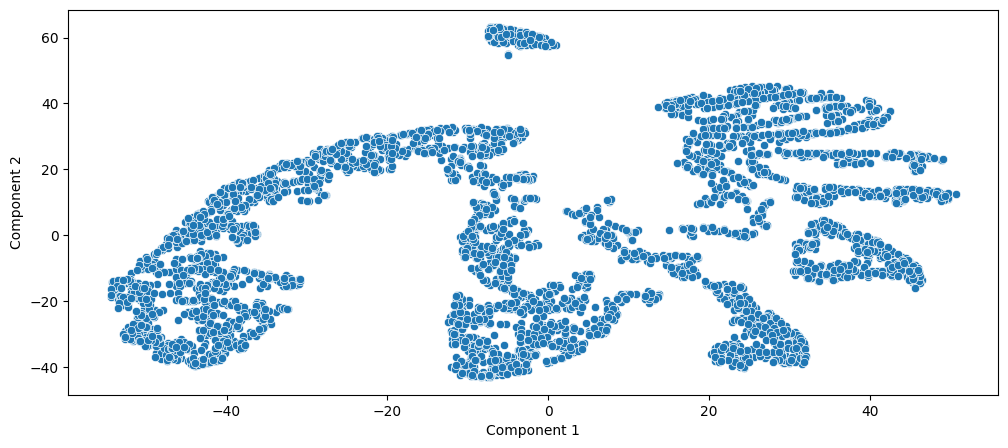

In [64]:
fig = plt.figure(figsize=(12, 5))
sns.scatterplot(data=rfm_pca_df_tsne, x='Component 1', y='Component 2');

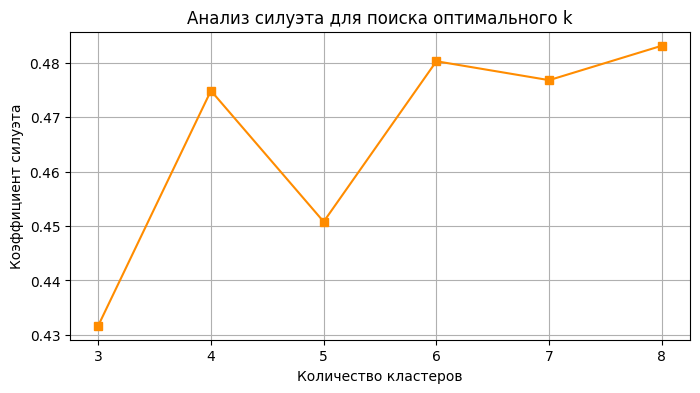

[0.43 0.47 0.45 0.48 0.48 0.48]


In [65]:
# 5.2
# Используем Kmeans. Найдем оптимальное количество кластеров.
# Создадим функцию, для подсчета лучшего коэффициента силуэта и оптимального количества кластеров
def get_silhouette(cluster_num, rfm_pca_df_tsne):
    kmeans = KMeans(init='k-means++', n_clusters=cluster_num, random_state=42)
    kmeans.fit(rfm_pca_df_tsne)
    silhouette = silhouette_score(rfm_pca_df_tsne, kmeans.labels_)
    return silhouette

silhouette = []
for cluster_num in range(3,9):
    silhouette.append(get_silhouette(cluster_num, rfm_pca_df_tsne))

# Создаем график для коэффициента силуэта   
plt.figure(figsize=(8, 4))
plt.plot(range(3, 9), silhouette, marker='s', color='darkorange')
plt.title('Анализ силуэта для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.grid(True)
plt.show()

print(np.round(silhouette,2))

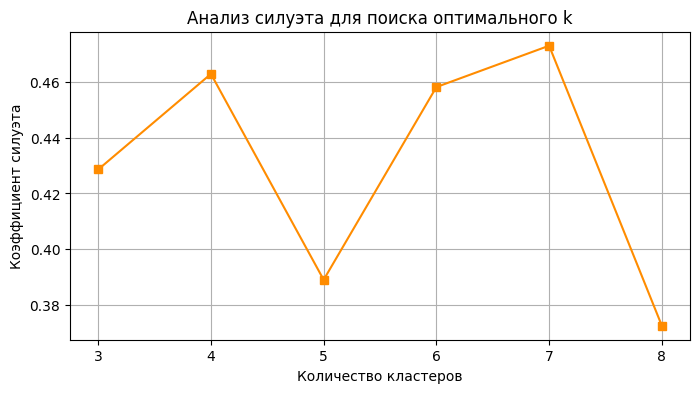

[0.43 0.46 0.39 0.46 0.47 0.37]


In [66]:
# 5.3
# Повторим, использую EM-алгоритм
def get_silhouette(cluster_num, rfm_pca_df_tsne):
    em = GaussianMixture(n_components=cluster_num, random_state=42)
    labels = em.fit_predict(rfm_pca_df_tsne)
    silhouette = silhouette_score(rfm_pca_df_tsne, labels)
    return silhouette

silhouette = []
for cluster_num in range(3,9):
    silhouette.append(get_silhouette(cluster_num, rfm_pca_df_tsne))
    
plt.figure(figsize=(8, 4))
plt.plot(range(3, 9), silhouette, marker='s', color='darkorange')
plt.title('Анализ силуэта для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.grid(True)
plt.show()

print(np.round(silhouette,2))